<h1 style='font-weight:bold; color:#003366; text-align:center;'>Solución del práctico del Parcial de prueba</h1>

<h3 style='font-weight:bold; color:#003366; text-align:center;'>Programación Analítica II</h3>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Docente Camila Palomeque</h4>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>S2 . 2026</h4>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

c:\Users\Camila Palomeque\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## <span style='color:#003366;'>Ejercicio 1 (24 puntos)</span>

<div style='border-left:5px solid #003366; background:#F0F4F8; padding:10px 14px;'>
Distribuidora agroindustrial. La facturación del semestre creció y el resultado cayó. La dirección sospecha de los descuentos que autorizan los vendedores.
</div>

In [4]:
# Datos de prueba (identicos a los del simulacro)

facturas = pd.DataFrame({
    "id_factura": ["FA-1001", "FA-1002", "FA-1003", "FA-1004", "FA-1005",
                   "FA-1006", "FA-1007", "FA-1008", "FA-1009", "FA-1010"],
    "linea_producto": ["Equipamiento", "Repuestos", "Insumos", "Servicio tecnico",
                       "Accesorios", "Equipamiento", "Repuestos", "Insumos",
                       "Servicio tecnico", "Accesorios"],
    "unidades": [2, 12, 40, 1, 25, 1, 8, 60, 2, 15],
    "precio_unitario": [38000.0, 1450.0, 320.0, 24000.0, 890.0,
                        52000.0, 2100.0, 295.0, 18500.0, 1250.0],
    "descuento": [0.10, 0.00, 0.20, 0.00, 0.15, 0.25, 0.10, 0.25, 0.00, 0.10],
    "costo_unitario": [26000.0, 1100.0, 260.0, 9000.0, 640.0,
                       34000.0, 1600.0, 250.0, 7200.0, 850.0],
    "costo_flete": [1800.0, 950.0, 1200.0, 0.0, 780.0,
                    2100.0, 1100.0, 1450.0, 0.0, 640.0],
})

facturas["facturacion"] = (
    facturas["unidades"] * facturas["precio_unitario"] * (1 - facturas["descuento"])
)
facturas["costo_total"] = (
    facturas["unidades"] * facturas["costo_unitario"] + facturas["costo_flete"]
)
facturas["margen"] = facturas["facturacion"] - facturas["costo_total"]

display(facturas)

,id_factura,linea_producto,unidades,precio_unitario,descuento,costo_unitario,costo_flete,facturacion,costo_total,margen
0,FA-1001,Equipamiento,2,"38,000.00",0.10,"26,000.00","1,800.00","68,400.00","53,800.00","14,600.00"
1,FA-1002,Repuestos,12,"1,450.00",0.00,"1,100.00",950.00,"17,400.00","14,150.00","3,250.00"
2,FA-1003,Insumos,40,320.00,0.20,260.00,"1,200.00","10,240.00","11,600.00","-1,360.00"
3,FA-1004,Servicio tecnico,1,"24,000.00",0.00,"9,000.00",0.00,"24,000.00","9,000.00","15,000.00"
4,FA-1005,Accesorios,25,890.00,0.15,640.00,780.00,"18,912.50","16,780.00","2,132.50"
5,FA-1006,Equipamiento,1,"52,000.00",0.25,"34,000.00","2,100.00","39,000.00","36,100.00","2,900.00"
6,FA-1007,Repuestos,8,"2,100.00",0.10,"1,600.00","1,100.00","15,120.00","13,900.00","1,220.00"
7,FA-1008,Insumos,60,295.00,0.25,250.00,"1,450.00","13,275.00","16,450.00","-3,175.00"
8,FA-1009,Servicio tecnico,2,"18,500.00",0.00,"7,200.00",0.00,"37,000.00","14,400.00","22,600.00"
9,FA-1010,Accesorios,15,"1,250.00",0.10,850.00,640.00,"16,875.00","13,390.00","3,485.00"


### <span style='color:#BB3300;'>Ejercicio 1 a), b) y c) : facturas con margen negativo (10 puntos)</span>

a) Cuántas facturas tienen margen negativo
b) Cuánto suman esas facturas
c) En qué línea de producto están


In [5]:
# Ejercicio 1 a), b) y c)

facturas_con_perdida = facturas[facturas["margen"] < 0]
display(facturas_con_perdida)
print(f"a) Facturas con margen negativo: {len(facturas_con_perdida)} de {len(facturas)}")


print(f"b) Facturación de las facturas con pérdida: {facturas_con_perdida['facturacion'].sum()}")


print("c) Lineas de producto donde estan:")
print(facturas_con_perdida["linea_producto"].value_counts())


,id_factura,linea_producto,unidades,precio_unitario,descuento,costo_unitario,costo_flete,facturacion,costo_total,margen
2,FA-1003,Insumos,40,320.00,0.20,260.00,"1,200.00","10,240.00","11,600.00","-1,360.00"
7,FA-1008,Insumos,60,295.00,0.25,250.00,"1,450.00","13,275.00","16,450.00","-3,175.00"


a) Facturas con margen negativo: 2 de 10
b) Facturación de las facturas con pérdida: 23515.0
c) Lineas de producto donde estan:
linea_producto
Insumos    2
Name: count, dtype: int64


### <span style='color:#BB3300;'>Ejercicio 1

**d)** *(10 puntos)* La política comercial de la empresa dice lo siguiente:

| Descuento aplicado | Etiqueta |
|---|---|
| Hasta 15% (inclusive) | `"Autorizado"` |
| Más de 15% | `"Fuera de politica"` |

Escribí una función llamada `clasificar_descuento(descuento)` que **devuelva** (con `return`) la etiqueta que corresponde. Usala para crear la columna `estado_descuento` en `facturas` y mostrá cuántas facturas hay en cada etiqueta.

In [8]:
# Ejercicio 1 d)

TOPE_DESCUENTO = 0.15



def clasificar_descuento(descuento):
    if descuento <= TOPE_DESCUENTO:
        return "Autorizado"
    else:
        return "Fuera de politica"

etiquetas = []
for descuento in facturas["descuento"]:
    etiquetas.append(clasificar_descuento(descuento))

facturas["estado_descuento"] = etiquetas

print("Facturas por etiqueta:")
print()
print(facturas["estado_descuento"].value_counts())

Facturas por etiqueta:

estado_descuento
Autorizado           7
Fuera de politica    3
Name: count, dtype: int64


## <span style='color:#003366;'>Ejercicio 2 (36 puntos)</span>

<div style='border-left:5px solid #003366; background:#F0F4F8; padding:10px 14px;'>
Sistemas manda la exportación de las facturas del mes, con los datos como vienen. Este ejercicio no usa el resultado del Ejercicio 1.
</div>

In [10]:
# Datos de prueba (identicos a los del simulacro)

facturas_mes = pd.DataFrame({
    "id_factura": ["FA-2001", "FA-2002", "FA-2003", "FA-2004", "FA-2005", "FA-2006",
                   "FA-2007", "FA-2008", "FA-2009", "FA-2010", "FA-2004", "FA-2011"],
    "id_cliente": ["C-01", "C-02", "C-03", "C-01", "C-04", "C-07",
                   "C-02", "C-03", "C-01", "C-04", "C-01", "C-02"],
    "linea_producto": ["Equipamiento", "Insumos", "Repuestos", "Equipamiento",
                       "Accesorios", "Insumos", "Equipamiento", "Repuestos",
                       "Accesorios", "Equipamiento", "Equipamiento", "Insumos"],
    "facturacion": [68400.0, 10240.0, 17400.0, 39000.0, 18912.5, 7300.0,
                    24000.0, 15120.0, 16875.0, 156000.0, 39000.0, 9450.0],
    "costo_flete": [1800.0, 1200.0, 950.0, 2100.0, 780.0, np.nan,
                    1450.0, 1100.0, 640.0, np.nan, 2100.0, 890.0],
})

display(facturas_mes)

,id_factura,id_cliente,linea_producto,facturacion,costo_flete
0,FA-2001,C-01,Equipamiento,"68,400.00","1,800.00"
1,FA-2002,C-02,Insumos,"10,240.00","1,200.00"
2,FA-2003,C-03,Repuestos,"17,400.00",950.00
3,FA-2004,C-01,Equipamiento,"39,000.00","2,100.00"
4,FA-2005,C-04,Accesorios,"18,912.50",780.00
5,FA-2006,C-07,Insumos,"7,300.00",NaN
6,FA-2007,C-02,Equipamiento,"24,000.00","1,450.00"
7,FA-2008,C-03,Repuestos,"15,120.00","1,100.00"
8,FA-2009,C-01,Accesorios,"16,875.00",640.00
9,FA-2010,C-04,Equipamiento,"156,000.00",NaN


### <span style='color:#BB3300;'>Ejercicio 2 a) : auditoría de calidad (15 puntos)</span>

**a)** *(15 puntos)* Auditá la calidad de `facturas_mes` antes de calcular nada. Mostrá con código:

1. Que columnas y tipos de datos hay.
2. Existen valores raros en variables categóricas y numéricas (value_counts() y describe()).
3. Hay problemas de calidad de datos (outliers, faltantes, repetidos).

En base al análisis, hay que corregir algún dato? Justifica tus decisiones.

In [13]:
# Ejercicio 2 a) . Paso 1: que hay en la tabla

print("Información general de la tabla:")
print(facturas_mes.info())

print("\nDimensiones:", facturas_mes.shape)

print("\nTipos de dato:")
print(facturas_mes.dtypes)

print("\nVariables:")
print(list(facturas_mes.columns))

print("\nFaltantes por columna:")
print(facturas_mes.isna().sum())

print("\nValores duplicados:")
print(facturas_mes.duplicated().sum())

Información general de la tabla:
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_factura      12 non-null     str    
 1   id_cliente      12 non-null     str    
 2   linea_producto  12 non-null     str    
 3   facturacion     12 non-null     float64
 4   costo_flete     10 non-null     float64
dtypes: float64(2), str(3)
memory usage: 863.0 bytes
None

Dimensiones: (12, 5)

Tipos de dato:
id_factura            str
id_cliente            str
linea_producto        str
facturacion       float64
costo_flete       float64
dtype: object

Variables:
['id_factura', 'id_cliente', 'linea_producto', 'facturacion', 'costo_flete']

Faltantes por columna:
id_factura        0
id_cliente        0
linea_producto    0
facturacion       0
costo_flete       2
dtype: int64

Valores duplicados:
1


In [17]:
# Ejercicio 2 a) Paso 2: categoricas
variables_categoricas = ["linea_producto", "id_cliente", "id_factura"]

for columna in variables_categoricas:
    print(f"{columna}")
    print(facturas_mes[columna].value_counts())
    print()

# Ver estadísticos de categóricas
display(facturas_mes.describe(include="O")) # o str dependiendo de la version de pandas

linea_producto
linea_producto
Equipamiento    5
Insumos         3
Repuestos       2
Accesorios      2
Name: count, dtype: int64

id_cliente
id_cliente
C-01    4
C-02    3
C-03    2
C-04    2
C-07    1
Name: count, dtype: int64

id_factura
id_factura
FA-2004    2
FA-2001    1
FA-2002    1
FA-2003    1
FA-2005    1
FA-2006    1
FA-2007    1
FA-2008    1
FA-2009    1
FA-2010    1
FA-2011    1
Name: count, dtype: int64



C:\Users\Camila Palomeque\AppData\Local\Temp\ipykernel_7028\1195977308.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(facturas_mes.describe(include="O")) # o str dependiendo de la version de pandas


,id_factura,id_cliente,linea_producto
count,12,12,12
unique,11,5,4
top,FA-2004,C-01,Equipamiento
freq,2,4,5


In [19]:
# Ejercicio 2 a) . Paso 3: numericas
display(facturas_mes[["facturacion", "costo_flete"]].describe().round(2))

,facturacion,costo_flete
count,12.00,10.00
mean,"35,141.46","1,301.00"
std,"41,816.45",537.39
min,"7,300.00",640.00
25%,"13,900.00",905.00
50%,"18,156.25","1,150.00"
75%,"39,000.00","1,712.50"
max,"156,000.00","2,100.00"


In [21]:
# Ejercicio 2 a) . Paso 4: la decision

# Elimino duplicados (factura repetida), me los quedo o qué hago
ventas = facturas_mes.drop_duplicates().copy()

# Los nulos en costo flete tienen sentido? los imputo hay diferencia entre media y mediana
display(ventas[ventas["costo_flete"].isna()])

# Algunas opciones:
#ventas["costo_flete"].fillna(ventas["costo_flete"].mean(), inplace=True)
#ventas["costo_flete"].fillna(ventas["costo_flete"].median(), inplace=True)
#ventas["costo_flete"].fillna(0, inplace=True)

#Hay un valor extremo en facturacion cuando miro el maximo 
display(ventas[ventas["facturacion"] == ventas["facturacion"].max()])

,id_factura,id_cliente,linea_producto,facturacion,costo_flete
5,FA-2006,C-07,Insumos,"7,300.00",NaN
9,FA-2010,C-04,Equipamiento,"156,000.00",NaN


,id_factura,id_cliente,linea_producto,facturacion,costo_flete
9,FA-2010,C-04,Equipamiento,"156,000.00",NaN


**b)** *(10 puntos)* Sobre `ventas`, armá un resumen **por línea de producto** con agregaciones con nombre:

| Columna del resumen | Qué mide |
|---|---|
| `facturas` | cantidad de facturas |
| `envio_promedio` | costo flete promedio por factura |
| `envio_mediano` | costo flete mediana por factura |

Después contestá: **¿en qué producto hay más variabilidad o valores raros del costo del envío?¿qué otros estadísticos podríamos usar para ver mejor esto?**

> *Pista: tema 5, `groupby` con `.agg()` y agregaciones con nombre. Las funciones que vimos son "count", "sum", "mean", "median", "min", "max", "std" y "nunique".*


In [22]:
# Ejercicio 2 b)
resumen_lineas = ventas.groupby("linea_producto").agg(
    facturas=("id_factura", "count"),
    envio_promedio=("costo_flete", "mean"),
    envio_mediano=("costo_flete", "median"),
)

display(resumen_lineas.round(2))

,facturas,envio_promedio,envio_mediano
linea_producto,,,
Accesorios,2,710.00,710.00
Equipamiento,4,"1,783.33","1,800.00"
Insumos,3,"1,045.00","1,045.00"
Repuestos,2,"1,025.00","1,025.00"


In [ ]:
# Ejercicio 2 b) Resumen ampliado para responder mejor la pregunta (Faltaria responderla con texto)

resumen_ampliado = ventas.groupby("linea_producto").agg(
    facturas=("id_factura", "count"),
    envios_cargados=("costo_flete", "count"),
    envio_promedio=("costo_flete", "mean"),
    envio_mediano=("costo_flete", "median"),
    envio_desvio=("costo_flete", "std"),
    envio_minimo=("costo_flete", "min"),
    envio_maximo=("costo_flete", "max"),
)

resumen_ampliado["recorrido"] = (
    resumen_ampliado["envio_maximo"] - resumen_ampliado["envio_minimo"]
)
resumen_ampliado["coef_variacion"] = (
    resumen_ampliado["envio_desvio"] / resumen_ampliado["envio_promedio"]
)

display(resumen_ampliado.sort_values("envio_desvio", ascending=False).round(2))

,facturas,envios_cargados,envio_promedio,envio_mediano,envio_desvio,envio_minimo,envio_maximo,recorrido,coef_variacion
linea_producto,,,,,,,,,
Equipamiento,4,3,"1,783.33","1,800.00",325.32,"1,450.00","2,100.00",650.00,0.18
Insumos,3,2,"1,045.00","1,045.00",219.20,890.00,"1,200.00",310.00,0.21
Repuestos,2,2,"1,025.00","1,025.00",106.07,950.00,"1,100.00",150.00,0.10
Accesorios,2,2,710.00,710.00,98.99,640.00,780.00,140.00,0.14


### <span style='color:#BB3300;'>Ejercicio 2 c) : el gráfico (10 puntos)</span>

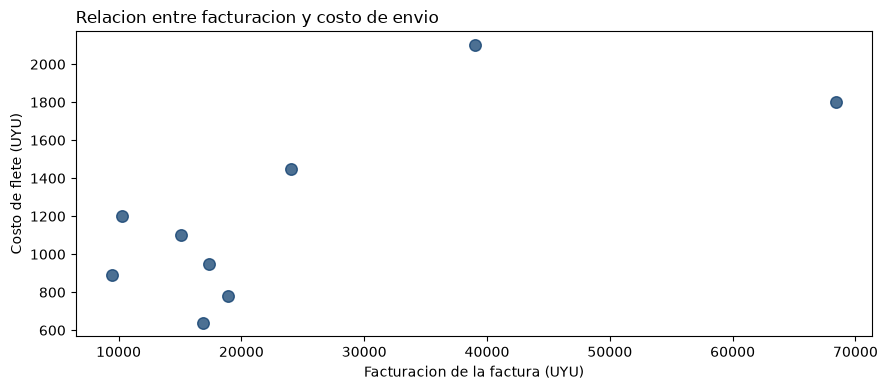

In [23]:
# Ejercicio 2 c)

fig, ax = plt.subplots(figsize=(9, 4))

ax.scatter(
    ventas["facturacion"],
    ventas["costo_flete"],
    alpha=0.7,
    s=70,
    color="#003366",
)

ax.set_title("Relacion entre facturacion y costo de envio", loc="left")
ax.set_xlabel("Facturacion de la factura (UYU)")
ax.set_ylabel("Costo de flete (UYU)")
fig.tight_layout()
plt.show()